# Лекция 1: Готовим рабочее место и пишем первый код


**Цель этого занятия:**
1.  Понять, из каких инструментов состоит "рабочее место" аналитика данных.
2.  Выбрать и подготовиться к установке своей рабочей среды.
3.  Познакомиться с Jupyter Notebook и написать первые строчки кода на Python.

> 🆘 **Если установка сегодня не взлетела** — не страшно: берите Google Colab (Путь 0 ниже), а дома спокойно ставьте нормально.

> ❗️ **Важно:** Сегодня мы все смотрим и обсуждаем. Ваша главная задача на дом — повторить установку по этому гайду на своем ноутбуке.

# Часть 1: Инструменты и Рабочее окружение


## Шаг 0: Командная строка (Терминал)

Прежде чем стать самураем данных, нужно научиться владеть своей катаной. Наша катана — это **командная строка** (она же **терминал**). Это способ общаться с компьютером напрямую, текстом, без мышки. Пугаться не надо, нам понадобится всего несколько команд.

*   **Windows:** `Win + R` -> `cmd` -> `Enter` (классика) ИЛИ `Win + X` -> `Windows Terminal` (современный вариант, внутри по умолчанию PowerShell — в нём `ls`, `pwd`, `cd` тоже работают).
*   **macOS:** `Cmd + Пробел` -> `Terminal` -> `Enter`.
*   **Linux:** Вы и так знаете :) `Ctrl + Alt + T` в большинстве систем.

**Мини-шпаргалка по командам:**

| Действие | Команда (macOS / Linux / WSL) | Команда (Windows CMD) |
| :--- | :--- | :--- |
| **Где я?** (показать текущую папку) | `pwd` | `cd` (без аргументов) |
| **Что здесь лежит?** (показать файлы) | `ls -la` | `dir` |
| **Перейти в папку** | `cd Documents` | `cd Documents` |
| **Вернуться на уровень выше** | `cd ..` | `cd ..` |

> 💡 **Совет:** Потратьте 15 минут, чтобы поиграться с этими командами. Это снимет 90% страха перед "черным экраном".

**Расширенная шпаргалка** (Windows vs macOS/Linux):

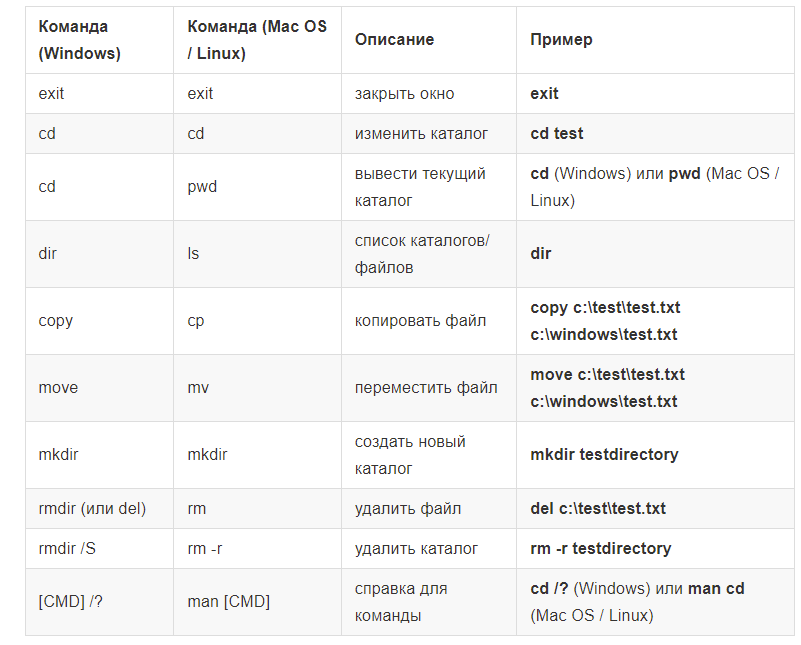

## Шаг 1: Выбираем способ установки Python + Jupyter

Есть несколько путей, как у богатыря на распутье. Выбирайте свой.

| Путь | Для кого | Зачем |
| :--- | :--- | :--- |
| **0. Google Colab** | Всем, у кого «не встало» | Ничего не ставим, работаем в браузере. Запасной вариант на первые занятия |
| **1. uv** ⭐ | **Рекомендуемый для всех** (Windows, macOS, Linux) | Одна утилита: сама ставит Python нужной версии, создаёт окружение, ставит библиотеки. Быстро |
| **2. WSL2 + uv** | Windows, кто готов к Linux | Настоящий Linux внутри Windows. **Во 2 семестре обязателен** — там Docker |
| **3. Miniforge / Anaconda** | Кто хочет «комбайн» | Запасной вариант, работает, но тяжелее |

Давайте разберем каждый.

### Путь 0: Google Colab (без установки)

Открываете [colab.research.google.com](https://colab.research.google.com), входите Google-аккаунтом, «Создать блокнот» — и у вас Jupyter в браузере с уже установленными pandas, numpy и matplotlib. Можно загрузить туда эту тетрадку (`Файл → Загрузить блокнот`).

Альтернативы, если Google недоступен: [Yandex DataSphere](https://datasphere.yandex.ru), [JupyterLite](https://jupyter.org/try-jupyter/lab/) (прямо в браузере, без аккаунта).

> ⚠️ Это **спасательный круг, а не дом**. Ботов (Л5–Л6) и веб-сервис (Л7) на Colab не сделать — к ним нужна локальная установка.

### Путь 1: uv (Рекомендуемый) ⭐

**uv** — современный менеджер Python-проектов. Одна маленькая программа заменяет сразу установщик Python, `venv` и `pip`, и работает одинаково на всех ОС.

> **Что такое виртуальное окружение?** Представьте, что для каждого проекта вы создаете отдельную, чистую "комнату" со своим набором инструментов. Это помогает избежать конфликтов версий библиотек. uv создает такую комнату (папку `.venv`) сам — вам даже не нужно ее «активировать».

**1. Установить uv** (одна команда, [официальная инструкция](https://docs.astral.sh/uv/getting-started/installation/)):
- **Windows** (PowerShell):
  ```powershell
  powershell -ExecutionPolicy ByPass -c "irm https://astral.sh/uv/install.ps1 | iex"
  ```
  или `winget install --id=astral-sh.uv -e`
- **macOS / Linux / WSL:**
  ```bash
  curl -LsSf https://astral.sh/uv/install.sh | sh
  ```
После установки **закройте и заново откройте терминал** и проверьте: `uv --version`.

**2. Создать проект курса** (uv сам скачает Python 3.13, если его нет):
```bash
uv init misis_course --no-package --python 3.13
cd misis_course
```

**3. Поставить библиотеки:**
```bash
uv add jupyterlab pandas numpy matplotlib seaborn
```

**4. Запустить Jupyter:**
```bash
uv run jupyter lab
```

> 💡 Нужна новая библиотека? `uv add название` в терминале, в папке проекта. Список всех библиотек проекта лежит в файле `pyproject.toml`.

### Путь 2: WSL2 + uv (Продвинутый, для Windows)

**WSL** — это магия от Microsoft, которая позволяет запускать Linux прямо внутри Windows без виртуальных машин. Вы получаете всю мощь Linux-терминала и инструментов.

**Почему это круто?**
- Многие инструменты для Data Science изначально создавались под Linux.
- Ваше рабочее окружение будет идентично тому, что используется на серверах.

**Как ставить:**
1.  **Установить WSL.** Откройте `Windows Terminal` **от имени администратора** и введите команду: `wsl --install`. Она установит все необходимое и дистрибутив Ubuntu по умолчанию. Перезагрузитесь.
2.  **Запустить Ubuntu.** Найдите в меню "Пуск" приложение Ubuntu. При первом запуске оно попросит создать имя пользователя и пароль.
3.  **Обновить пакеты.** Внутри терминала Ubuntu выполните:
    ```bash
    sudo apt update
    sudo apt upgrade
    ```
4.  **Дальше — Путь 1 (uv)**, команды для macOS / Linux / WSL. Всё ставим и запускаем **внутри Ubuntu**.

> 🐳 Во 2 семестре мы будем работать с **Docker**, а на Windows он работает через WSL2. Так что WSL всё равно понадобится — можно поставить сразу.

> 💡 Папки Windows видны из Ubuntu как `/mnt/c/...`, но проект лучше держать в домашней папке Linux (`~/misis_course`) — так всё работает в разы быстрее. VS Code открывает её командой `code .` из терминала Ubuntu.

### Путь 3: Miniforge / Anaconda (Комбайн)

**Anaconda** — это как швейцарский нож: сам Python, Jupyter, сотни предустановленных библиотек (pandas, numpy, scikit-learn) и менеджер пакетов `conda`. Минус — он тяжелый (несколько гигабайт).

> ⚖️ **Про лицензию.** Anaconda Distribution бесплатна для частного лица, но в организациях от 200 человек нужна лицензия; для вузов она бесплатна, только если у университета есть академическое соглашение с Anaconda. Чтобы не разбираться — ставьте **[Miniforge](https://conda-forge.org/download/)**: та же `conda`, но с бесплатным каналом conda-forge.

**Как ставить Miniforge:**
1.  Скачиваете установщик для вашей ОС со [страницы загрузки](https://conda-forge.org/download/) и запускаете, на все вопросы — "Далее".
2.  Открываете **Miniforge Prompt** (Windows) или новый терминал (macOS/Linux) и создаете окружение:
    ```bash
    conda create -n misis python=3.13 jupyterlab pandas numpy matplotlib seaborn
    conda activate misis
    jupyter lab
    ```

> ❗️ Docker от выбора Anaconda никак не зависит — просто на Windows ему в любом случае нужен WSL2 (см. Путь 2).

<details>
<summary><b>Для любопытных: «классический» путь — python + venv + pip</b> (раскройте)</summary>

Так окружения делали до uv, и вы будете встречать это во всех инструкциях в интернете:

```bash
python3 -m venv .venv            # Windows: py -m venv .venv
source .venv/bin/activate        # Windows: .venv\Scripts\activate
pip install jupyterlab pandas
```

Грабли, на которые наступают чаще всего:
- **macOS больше не поставляется с Python** — команда `python3` предложит поставить Xcode Command Line Tools.
- **Ubuntu / WSL:** `python3 -m venv` падает, пока не сделать `sudo apt install python3-venv`; а `pip install` вне окружения выдает ошибку `externally-managed-environment` — это не баг, а защита системного Python (PEP 668). Ставьте библиотеки только внутри окружения.
- **Windows PowerShell:** активация падает с ошибкой «выполнение сценариев отключено» → один раз выполнить `Set-ExecutionPolicy -Scope CurrentUser RemoteSigned`.

uv все эти грабли обходит сам — поэтому он у нас Путь 1.
</details>

## Шаг 2: Редактор кода — VS Code

Jupyter Lab в браузере — отличный старт, но уже на Л5–Л7 (боты, веб) нам понадобятся обычные `.py`-файлы и терминал. Поэтому удобнее с первого дня работать в одной среде:

- **[VS Code](https://code.visualstudio.com/)** + расширения **Python** и **Jupyter** (от Microsoft). Открываете папку проекта (`File → Open Folder`), создаете `homework_01.ipynb`, справа сверху «Select Kernel» → выбираете окружение `.venv` из папки проекта.
- Альтернатива: **PyCharm** (бесплатная версия тоже умеет Jupyter).
- **ИИ-ассистенты** встроены в оба редактора. Пользоваться можно — правила игры обсудили на слайде «Политика по ИИ».

------

A few things before we start:

- Автор тетрадки: Воробьев Даниил @herrenot
- Использовались очевидные заимствования отовсюду подряд, материал никак не претендует на уникальность. Однако, любые опечатки и неточности, конечно же, исключительно на моей совести
- Курс рассчитан на Python 3.13 (3.14 тоже подойдет). Python 3.15 вышел 9 октября 2026 — библиотеки еще догоняют, начинать на нем не стоит
- Я мало пишу на русском. Замечания про опечатки, отсутствующие запятые и несогласованные предложения приветствуются

# Часть 2: Первое погружение в Python

**Цели этой части:**
- Понять, как работать в среде Jupyter Notebook/Lab.
- Научиться выводить информацию на экран и оставлять комментарии.
- Разобраться с главной концепцией программирования — **переменными**.
- Изучить базовые типы данных: числа, строки, булевы значения.
- Освоить современный и удобный способ форматирования строк (f-strings).
- Научиться делать простые математические операции.
- Сделать нашу программу интерактивной с помощью функции `input()`.

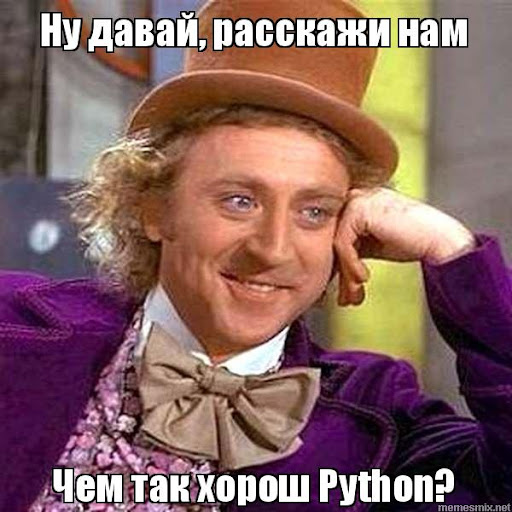

## Что такое Jupyter? Наш цифровой лабораторный журнал

Представьте себе тетрадь, в которой можно не только писать текст, формулы и вставлять картинки, но и тут же писать и **выполнять** программный код, сразу видя результат. Это и есть Jupyter.

**Ключевые особенности:**
- **Ячейки (cells):** Это "кирпичики", из которых состоит наша тетрадь. Они бывают двух основных типов:
    - **`Code`**: для кода на Python.
    - **`Markdown`**: для форматированного текста, заголовков, списков, ссылок и картинок (как эта ячейка).
- **Интерактивность:** Мы можем выполнять ячейки по одной, в любом порядке, и сразу видеть результат. Это идеально для исследования данных.

**🔥 Самые важные горячие клавиши (научитесь им, и ваша скорость вырастет в разы):**
- `Shift + Enter`: **Выполнить** текущую ячейку и перейти на следующую.
- `Ctrl + Enter`: Выполнить текущую ячейку и остаться в ней.
- `Esc`: Переключиться в командный режим (ячейка станет синей).
- В командном режиме:
    - `A` (Above): Создать новую ячейку **выше** текущей.
    - `B` (Below): Создать новую ячейку **ниже** текущей.
    - `M`: Превратить ячейку в текстовую (**M**arkdown).
    - `Y`: Превратить ячейку в кодовую (Code, `Y` - исторически сложилось).
    - `DD` (дважды нажать `D`): Удалить текущую ячейку.

In [1]:
# Это ячейка с кодом. Давайте выполним ее, нажав Shift + Enter.
print("Привет, мир анализа данных!")

Привет, мир анализа данных!


### ⚠️ Ядро и порядок выполнения (самая частая причина «у меня работало!»)

- За тетрадкой стоит **ядро (kernel)** — запущенный Python, который **помнит** все, что вы выполнили. Не то, что написано на экране, а то, что **выполнялось**, и **в том порядке**, в каком вы жали `Shift + Enter`.
- Номер в `[ ]` слева от ячейки — порядок выполнения. Если номера скачут (`[7]`, `[3]`, `[12]`), значит, ячейки выполнялись вразнобой, и результат может зависеть от удаленных или измененных ячеек.
- **Перед сдачей ДЗ:** `Kernel → Restart Kernel and Run All Cells` (в VS Code — `Restart` и `Run All`). Если тетрадка прошла сверху вниз без ошибок — можно сдавать.
- Что-то зависло или «сломалось все»? Тоже **Restart Kernel**.

**Полезные мелочи:**
- `Tab` — автодополнение имен; `Shift + Tab` — подсказка по функции.
- `print?` или `help(print)` — справка по любой функции.
- Поставить библиотеку **прямо из тетрадки**: `%pip install название` (Colab, conda). В проекте uv — `uv add название` в терминале.

### Функция `print()` и Комментарии

- **`print()`** — это наша основная команда, чтобы "поговорить" с пользователем. Она выводит на экран все, что мы передадим ей в скобках.
- **Комментарии** — это текст, который Python полностью игнорирует. Он нужен только для нас, людей, чтобы оставлять пометки и объяснения в коде. Комментарий начинается со знака `#`.

### Переменные: "коробки" для данных

Представьте, что переменная — это коробка, на которой есть этикетка (имя переменной). Мы можем положить в эту коробку какие-то данные (число, текст), а потом в любой момент обратиться к ней по имени, чтобы посмотреть или использовать то, что внутри.

**Правила именования переменных (snake_case):**
- Имена могут содержать буквы, цифры и `_`.
- Имя не может начинаться с цифры.
- Имена чувствительны к регистру (`my_box` и `My_Box` — это две разные переменные).
- **Стандарт стиля в Python (PEP8):** имена переменных пишутся маленькими буквами, а слова разделяются нижним подчеркиванием. Например: `student_count`, `average_price`.

In [2]:
# Создаем переменную `lecturer_name` и кладем в нее строку 'Даниил'
lecturer_name = "Даниил"
course_year = 2026
students_in_group = 25

# Теперь мы можем использовать эти переменные
print("Имя преподавателя:", lecturer_name)
print("Год проведения курса:", course_year)
print("Студентов в группе:", students_in_group)

# Значение в переменной можно поменять (перезаписать)
students_in_group = 26
print("Ой, один студент добавился! Теперь в группе:", students_in_group)

Имя преподавателя: Даниил
Год проведения курса: 2026
Студентов в группе: 25
Ой, один студент добавился! Теперь в группе: 26


### Базовые типы данных

У каждой "коробки" (переменной) есть тип содержимого. Вот самые главные:

- **`int`** (integer): **Целые числа**. Например: `10`, `0`, `-150`.
- **`float`**: **Числа с плавающей точкой**. Например: `3.14`, `99.9`, `-0.01`. (Разделитель - точка!)
- **`str`** (string): **Строки (текст)**. Все, что в одинарных `'` или двойных `"` кавычках.
- **`bool`** (boolean): **Логический тип**. Может принимать только два значения: `True` (Истина) или `False` (Ложь). С большой буквы!
- **`None`**: **«Ничего»**. Специальное значение «тут пока пусто» (например, пользователь еще не ввел данные).

Узнать тип данных в переменной можно с помощью встроенной функции `type()`.

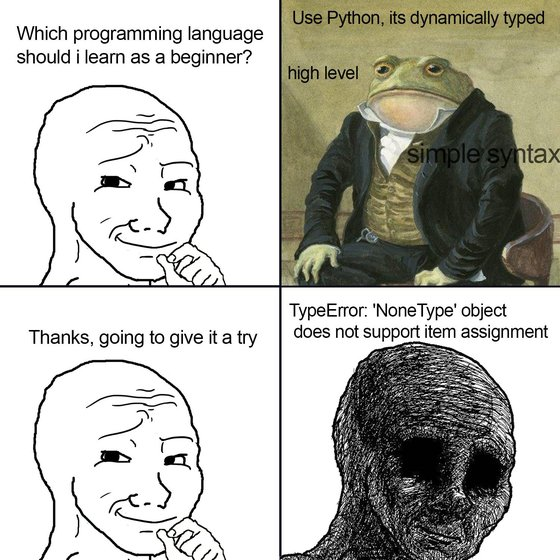

*«Учи Python, там динамическая типизация, всё просто». Через неделю: `TypeError: 'NoneType' object does not support item assignment`. Тип у переменной есть всегда — просто Python спрашивает о нём не при написании кода, а в момент падения. Знакомьтесь: `None` из ячейки ниже — главный поставщик таких ошибок.*

In [3]:
project_id = 14887          # int
avg_temperature = -15.5     # float
city_name = "Санкт-Петербург" # str
is_course_active = True     # bool
homework_grade = None       # NoneType

print(f"Переменная 'project_id' имеет тип: {type(project_id)}")
print(f"Переменная 'avg_temperature' имеет тип: {type(avg_temperature)}")
print(f"Переменная 'city_name' имеет тип: {type(city_name)}")
print(f"Переменная 'is_course_active' имеет тип: {type(is_course_active)}")
print(f"Переменная 'homework_grade' имеет тип: {type(homework_grade)}")

Переменная 'project_id' имеет тип: <class 'int'>
Переменная 'avg_temperature' имеет тип: <class 'float'>
Переменная 'city_name' имеет тип: <class 'str'>
Переменная 'is_course_active' имеет тип: <class 'bool'>
Переменная 'homework_grade' имеет тип: <class 'NoneType'>


## Как выводить переменные на экран? Три способа.

Итак, у нас есть данные в "коробках"-переменных. Как нам показать их пользователю? Есть несколько способов, от простого к самому мощному.

### Способ 1: Перечисление в `print()` (Самый простой старт)

Функция `print()` очень умная. Ей можно передать несколько значений через запятую, и она сама выведет их через пробел. Это идеальный способ для быстрого вывода.

In [4]:
city_name = "Москва"
temperature = -5
units = "градусов"

# Просто перечисляем переменные и текст через запятую
print("В городе", city_name, "сейчас", temperature, units)

# Это работает с любыми типами, ничего не нужно преобразовывать!
student_count = 25
print("На лекции присутствует", student_count, "студентов.")

В городе Москва сейчас -5 градусов
На лекции присутствует 25 студентов.


### Способ 2: Сложение строк (Старый, "топорный" способ)

Иногда нам нужно не просто вывести текст на экран, а **создать одну целую строку** и сохранить ее в новую переменную. Первое, что приходит в голову — сложить строки, как мы складываем числа. Это называется **конкатенация**.

**Но здесь нас поджидают две ловушки:**
1.  Складывать можно **только строки со строками**. Если попытаться сложить строку и число, будет ошибка `TypeError`.
2.  Придется вручную добавлять все пробелы.

In [5]:
# Попробуем сложить строки
greeting = "Привет, "
name = "Алекс"
message = greeting + name
print(message)

# А теперь попробуем добавить число...
age = 30

# Эта ячейка вызовет ошибку! Раскомментируйте, чтобы проверить.
# full_message = "Возраст пользователя: " + age 

# Как это исправить? Превратить число в строку с помощью str()
full_message = "Возраст пользователя: " + str(age)
print(full_message)

# Как видите, это громоздко и легко ошибиться. Мы не будем использовать этот способ.

Привет, Алекс
Возраст пользователя: 30


### Способ 3: F-строки (Современный, мощный и рекомендуемый способ)

**F-строки** (форматированные строки) были введены в Python 3.6 и сразу стали стандартом. Они решают все проблемы предыдущего способа.

**Как это работает:**
1.  Перед кавычками ставится буква `f`.
2.  Внутри строки, в фигурных скобках `{}`, вы пишете имена переменных.
3.  Python сам подставит значения переменных на их место и автоматически преобразует их в строки.

Это элегантно, читаемо и очень мощно. **Именно этот способ мы будем использовать на протяжении всего курса.**

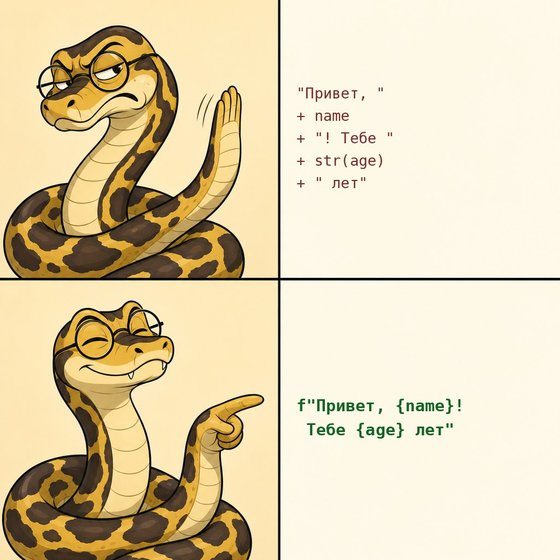

*Сложение строк против f-строки. Змея знает, как правильно.*

In [6]:
city_name = "Казань"
temperature = 15

# Создаем сообщение с помощью f-строки
report = f"Погода в городе {city_name}: {temperature} градусов."
print(report)

# Можно использовать сколько угодно переменных
student_name = "Мария"
grade = 4.85
report_card = f"Студентка {student_name} имеет средний балл {grade}."
print(report_card)



Погода в городе Казань: 15 градусов.
Студентка Мария имеет средний балл 4.85.


### Базовые операции

**Арифметические операции (с числами):**

In [7]:
a = 20
b = 7

print(f"{a} + {b} = {a + b}")    # Сложение
print(f"{a} * {b} = {a * b}")    # Умножение
print(f"{a} / {b} = {a / b}")    # Обычное деление, результат всегда float

print("--- Специальные виды деления ---")
print(f"Целочисленное деление: {a} // {b} = {a // b}") # Сколько ЦЕЛЫХ раз b помещается в a
print(f"Остаток от деления: {a} % {b} = {a % b}")   # Что останется (очень полезно для проверки на четность)
print(f"Возведение в степень: 5 ** 2 = {5 ** 2}") # 5 в квадрате

20 + 7 = 27
20 * 7 = 140
20 / 7 = 2.857142857142857
--- Специальные виды деления ---
Целочисленное деление: 20 // 7 = 2
Остаток от деления: 20 % 7 = 6
Возведение в степень: 5 ** 2 = 25


In [8]:
20+7

27

In [9]:
0.3+0.3

0.6

In [10]:
0.3+0.3+0.3

0.8999999999999999

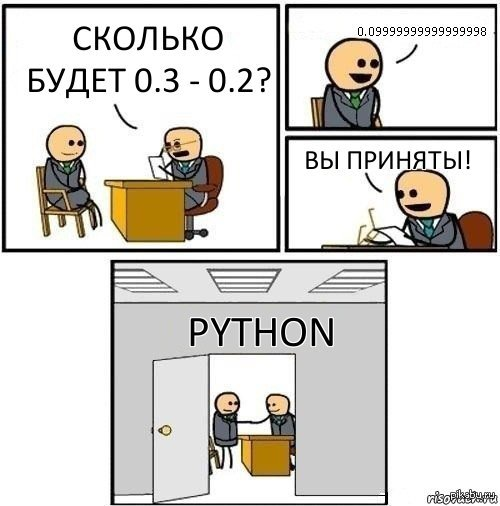

Почему `0.3 + 0.3 + 0.3` не равно `0.9`? Компьютер хранит дробные числа в **двоичном** виде, а `0.1` или `0.3` в двоичной системе — бесконечная дробь (как `1/3 = 0.333...` у нас). Поэтому появляется крошечная погрешность. Это не баг Python — так считают почти все языки программирования.

**Как жить:** округлять при выводе и не сравнивать дробные числа через `==`.

In [11]:
import math

print(0.3 - 0.2)
print(round(0.3 - 0.2, 2))                # округлить до 2 знаков
print(f"{0.3 - 0.2:.2f}")                 # или округлить прямо в f-строке
print(0.3 - 0.2 == 0.1)                   # сравнивать дроби через == опасно
print(math.isclose(0.3 - 0.2, 0.1))       # а так правильно: «почти равны?»

0.09999999999999998
0.1
0.10
False
True


**Операции со строками:**

In [12]:
first_name = "Илон"
last_name = "Маск"

# Сложение строк (конкатенация)
full_name = first_name + " " + last_name
print(full_name)

# Умножение строки на число (повторение)
separator = "-="
print(separator * 20)

# У строк есть "встроенные функции" - методы. Например, для изменения регистра
phrase = "Мама мыла раму"
print(f"Оригинал: {phrase}")
print(f"Все буквы заглавные: {phrase.upper()}")
print(f"Все буквы строчные: {phrase.lower()}")
print(f"Первые буквы заглавные: {phrase.title()}")

Илон Маск
-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=
Оригинал: Мама мыла раму
Все буквы заглавные: МАМА МЫЛА РАМУ
Все буквы строчные: мама мыла раму
Первые буквы заглавные: Мама Мыла Раму


### Интерактивность: функция `input()`

А что, если мы хотим, чтобы программа задавала вопросы пользователю и работала с его ответами? Для этого есть функция `input()`.

**❗️ ОЧЕНЬ ВАЖНЫЙ МОМЕНТ:** Функция `input()` **всегда** возвращает **строку (`str`)**, даже если пользователь ввел цифры!

In [13]:
user_name = input("Как вас зовут? ")
print(f"Привет, {user_name}! Очень приятно познакомиться.")

user_city = input(f"{user_name}, а из какого вы города? ")
print(f"О, {user_city} — отвратительный город!!! ")

Как вас зовут?  Аня
Привет, Аня! Очень приятно познакомиться.
Аня, а из какого вы города?  Казань
О, Казань — отвратительный город!!! 


In [14]:
# Демонстрация проблемы с типами
birth_year_str = input("Введите ваш год рождения: ")

# Проверим тип данных
print(f"Тип данных, который мы получили от input(): {type(birth_year_str)}")

# Попытаемся прибавить к "году" единицу
# Эта ячейка вызовет ошибку TypeError! Это нормально.
# age = birth_year_str + 1 

Введите ваш год рождения:  2007
Тип данных, который мы получили от input(): <class 'str'>


In [15]:
age = birth_year_str + 1 

TypeError: can only concatenate str (not "int") to str

### Преобразование типов (Type Casting)

Чтобы решить проблему выше, нам нужно явно превратить строку в число. Для этого есть функции `int()` и `float()`.

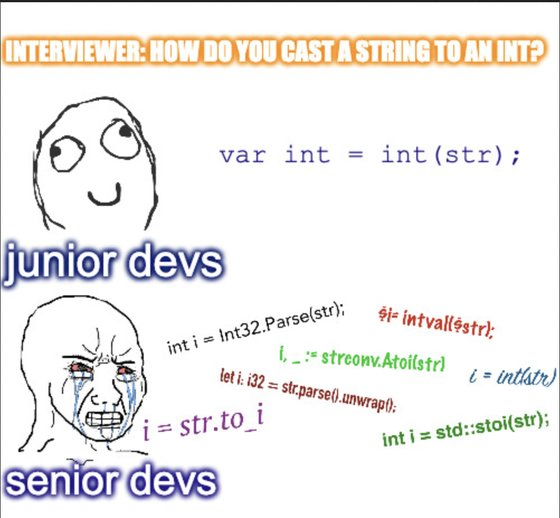

*Python-джун: `int(s)`. Сеньор, повидавший C, C# и JavaScript, — плачет.*

In [16]:
birth_year_str = input("Давайте еще раз. Введите ваш год рождения: ")

# Превращаем строку в целое число
birth_year_int = int(birth_year_str) 

# Теперь все работает!
current_year = 2026
age = current_year - birth_year_int

print(f"Вам примерно {age} лет.")

Давайте еще раз. Введите ваш год рождения:  2007
Вам примерно 19 лет.


## Собираем всё вместе: Мини-проект "Калькулятор шаурмы"

Давайте напишем программу, которая посчитает стоимость заказа в шаурмичной.

In [17]:
# 1. Приветствуем пользователя
print("Добро пожаловать в лучшую шаурмичную!")
print("-" * 30)

# 2. Узнаем цены (для примера они у нас фиксированные)
shawarma_price = 250.0  # float, так как цена может быть не целой
drink_price = 80.5

# 3. Спрашиваем у пользователя, сколько чего он хочет
shawarma_count_str = input(f"Сколько шаурм по {shawarma_price} руб. вы хотите? ")
drink_count_str = input(f"Сколько напитков по {drink_price} руб. вы хотите? ")

# 4. Преобразуем строки в числа
shawarma_count = int(shawarma_count_str)
drink_count = int(drink_count_str)

# 5. Считаем итоговую стоимость
total_cost = (shawarma_count * shawarma_price) + (drink_count * drink_price)

# 6. Выводим красивый чек
print("-" * 30)
print("ВАШ ЧЕК:")
print(f"Шаурма: {shawarma_count} шт. x {shawarma_price} руб.")
print(f"Напиток: {drink_count} шт. x {drink_price} руб.")
print("-" * 30)
print(f"ИТОГО К ОПЛАТЕ: {total_cost:.2f} руб.")
print("Спасибо за заказ!")

Добро пожаловать в лучшую шаурмичную!
------------------------------
Сколько шаурм по 250.0 руб. вы хотите?  2
Сколько напитков по 80.5 руб. вы хотите?  1
------------------------------
ВАШ ЧЕК:
Шаурма: 2 шт. x 250.0 руб.
Напиток: 1 шт. x 80.5 руб.
------------------------------
ИТОГО К ОПЛАТЕ: 580.50 руб.
Спасибо за заказ!


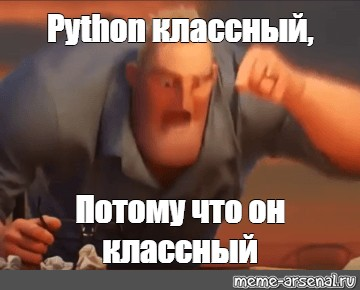

## Домашнее задание: "Миссия: Развертывание"

Ваша задача — к следующему занятию прийти с полностью настроенным рабочим ноутбуком.

**1.**
   - Выбрать один из путей установки (рекомендуем uv).
   - Установить все по инструкции из этой тетрадки (если застряли — спросите ИИ-ассистента, приложив текст ошибки).
   - Поставить VS Code с расширениями Python и Jupyter (или PyCharm).
   - Запустить Jupyter Lab/Notebook.
   - Создать новую тетрадку с именем `homework_01.ipynb`.
   - В первой ячейке написать код: `print("Меня зовут [Ваше Имя], и я готов(а) страдать на курсе!")`
   - Перед этим сделать `Restart Kernel and Run All`.
   - Сделать скриншот результата (чтобы было видно и код, и результат) и прислать в наш телеграм-чат.

**2.**
- В той же тетрадке создайте ячейку Markdown и напишите в ней пару предложений о себе, используя заголовки и списки.
- Найдите остаток от деления 77 на 2
- Узнайте четное ли число 22
- Посчитайте 86 в степени 7
- Найдите квадратный корень из 3686400 (подсказка: корень — это степень `0.5`)

**3.** Заведите аккаунт на [GitHub](https://github.com) — со следующей лекции ДЗ сдаем через него.


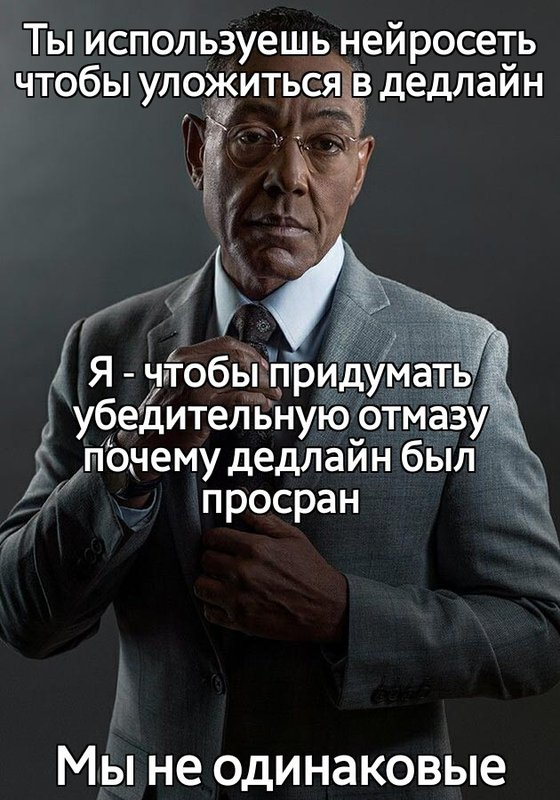

*Нейросетью пользоваться можно (см. политику ИИ). Но на собеседовании отвечать будете вы, а не она.*